## Next-Day OEE Prediction using Machine Learning

### Problem Statement -

### Library import 

In [6]:
import os
import pickle
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from scipy.stats import shapiro, zscore
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss

from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score,mean_absolute_percentage_error)

warnings.filterwarnings("ignore")

### Data Gathering

In [7]:
os.listdir(os.getcwd())

['.ipynb_checkpoints',
 'anaconda_projects',
 'Code1_Predict_Tomorrow_OEE.ipynb',
 'Code2_Load_Model_Predict_OEE.ipynb']

In [8]:
df = pd.read_csv("../Data/OEE data Aug 2026 _sheet 1.csv")
df.head()

,Sr.No,Machine_No,Date,Shift,Customer,Part_Name,Avail_Hrs,MC_Running_Hrs,Total_DT,Prod_Qty,Rej_Qty,Good_Qty,Cycle_Time(s),A,P,Q,Machine_Age,Operator_Team,Maintenance_Flag,OEE
0,1,FERROMATIC(3),01-08-2026,A,NaN,Gearbox,8.11,7.46,0.65,447,15,432.0,46,91.99,76.56,96.64,3,Team-3,Yes,68.06
1,2,FERROMATIC(4),01-08-2026,B,Tata,Sunroof,8.58,8.08,0.50,437,18,419.0,47,94.17,70.61,95.88,10,Team-3,No,63.75
2,3,FERROMATIC(1),01-08-2026,A,Mahindra,Gearbox,8.43,7.94,0.49,401,21,NaN,50,94.19,70.14,94.76,5,Team-2,Yes,62.60
3,4,FERROMATIC(1),01-08-2026,B,Mahindra,Panel,8.42,7.86,0.56,439,18,421.0,50,93.35,77.57,95.90,3,Team-1,NaN,69.44
4,5,FERROMATIC(3),01-08-2026,B,Tata,Gearbox,8.27,7.48,0.79,412,15,397.0,53,90.45,81.09,96.36,6,Team-2,Yes,70.68


### EDA - Exploratory Data Analysis.

##### -> Total numbers of rows and columns

In [9]:
df.shape
print ("total numbers of rows are", df.shape[0])
print ("total numbers of columns are", df.shape[1])

total numbers of rows are 1001
total numbers of columns are 20


#### -> Count of missing values

In [8]:
df.isna().sum()

Sr.No               0
Machine_No          0
Date                0
Shift               0
Customer            1
Part_Name           0
Avail_Hrs           0
MC_Running_Hrs      0
Total_DT            0
Prod_Qty            0
Rej_Qty             0
Good_Qty            1
Cycle_Time(s)       0
A                   0
P                   0
Q                   0
Machine_Age         0
Operator_Team       0
Maintenance_Flag    1
OEE                 0
dtype: int64

In [9]:
df.isnull().sum()

Sr.No               0
Machine_No          0
Date                0
Shift               0
Customer            1
Part_Name           0
Avail_Hrs           0
MC_Running_Hrs      0
Total_DT            0
Prod_Qty            0
Rej_Qty             0
Good_Qty            1
Cycle_Time(s)       0
A                   0
P                   0
Q                   0
Machine_Age         0
Operator_Team       0
Maintenance_Flag    1
OEE                 0
dtype: int64

##### ->Percetage of missing value

In [10]:
df.isna().mean()*100

Sr.No               0.0000
Machine_No          0.0000
Date                0.0000
Shift               0.0000
Customer            0.0999
Part_Name           0.0000
Avail_Hrs           0.0000
MC_Running_Hrs      0.0000
Total_DT            0.0000
Prod_Qty            0.0000
Rej_Qty             0.0000
Good_Qty            0.0999
Cycle_Time(s)       0.0000
A                   0.0000
P                   0.0000
Q                   0.0000
Machine_Age         0.0000
Operator_Team       0.0000
Maintenance_Flag    0.0999
OEE                 0.0000
dtype: float64

In [11]:
df.isnull().mean()*100

Sr.No               0.0000
Machine_No          0.0000
Date                0.0000
Shift               0.0000
Customer            0.0999
Part_Name           0.0000
Avail_Hrs           0.0000
MC_Running_Hrs      0.0000
Total_DT            0.0000
Prod_Qty            0.0000
Rej_Qty             0.0000
Good_Qty            0.0999
Cycle_Time(s)       0.0000
A                   0.0000
P                   0.0000
Q                   0.0000
Machine_Age         0.0000
Operator_Team       0.0000
Maintenance_Flag    0.0999
OEE                 0.0000
dtype: float64

##### ->data types of each columns

In [12]:
df.dtypes

Sr.No                 int64
Machine_No           object
Date                 object
Shift                object
Customer             object
Part_Name            object
Avail_Hrs           float64
MC_Running_Hrs      float64
Total_DT            float64
Prod_Qty              int64
Rej_Qty               int64
Good_Qty            float64
Cycle_Time(s)         int64
A                   float64
P                   float64
Q                   float64
Machine_Age           int64
Operator_Team        object
Maintenance_Flag     object
OEE                 float64
dtype: object

##### -> Counts how many records belong to each operator team

In [13]:
df["Operator_Team"].value_counts()

Operator_Team
Team-1    353
Team-3    324
Team-2    324
Name: count, dtype: int64

##### -> Calculates summary statistics for each column.

In [14]:
df.describe()

,Sr.No,Avail_Hrs,MC_Running_Hrs,Total_DT,Prod_Qty,Rej_Qty,Good_Qty,Cycle_Time(s),A,P,Q,Machine_Age,OEE
count,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000,1000.000000,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000
mean,500.004995,8.500420,7.867153,0.633267,415.443556,22.389610,393.067000,51.764236,92.547083,75.840529,94.596144,5.592408,66.375485
std,289.099507,0.290924,0.302785,0.123292,20.778332,4.542252,21.355809,3.508612,1.443351,4.315039,1.135111,2.857919,3.647954
min,1.000000,8.000000,7.230000,0.410000,380.000000,15.000000,352.000000,45.000000,89.950000,63.730000,92.150000,1.000000,56.800000
25%,250.000000,8.250000,7.620000,0.530000,397.000000,19.000000,375.000000,50.000000,91.330000,72.680000,93.650000,3.000000,63.850000
50%,500.000000,8.500000,7.860000,0.630000,415.000000,22.000000,393.000000,52.000000,92.590000,75.860000,94.670000,6.000000,66.380000
75%,750.000000,8.750000,8.110000,0.740000,434.000000,26.000000,412.000000,54.000000,93.760000,78.800000,95.530000,8.000000,68.900000
max,1000.000000,9.000000,8.510000,0.880000,450.000000,30.000000,434.000000,60.000000,95.020000,90.440000,96.660000,10.000000,76.770000


##### -> Check duplicates

In [15]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
996     False
997     False
998     False
999     False
1000    False
Length: 1001, dtype: bool

In [16]:
df.duplicated().sum()

np.int64(1)

In [17]:
df[df.duplicated()]

,Sr.No,Machine_No,Date,Shift,Customer,Part_Name,Avail_Hrs,MC_Running_Hrs,Total_DT,Prod_Qty,Rej_Qty,Good_Qty,Cycle_Time(s),A,P,Q,Machine_Age,Operator_Team,Maintenance_Flag,OEE
5,5,FERROMATIC(3),01-08-2026,B,Tata,Gearbox,8.27,7.48,0.79,412,15,397.0,53,90.45,81.09,96.36,6,Team-2,Yes,70.68


##### ->Quick overview of Dataset

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1001 entries, 0 to 1000
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Sr.No             1001 non-null   int64  
 1   Machine_No        1001 non-null   object 
 2   Date              1001 non-null   object 
 3   Shift             1001 non-null   object 
 4   Customer          1000 non-null   object 
 5   Part_Name         1001 non-null   object 
 6   Avail_Hrs         1001 non-null   float64
 7   MC_Running_Hrs    1001 non-null   float64
 8   Total_DT          1001 non-null   float64
 9   Prod_Qty          1001 non-null   int64  
 10  Rej_Qty           1001 non-null   int64  
 11  Good_Qty          1000 non-null   float64
 12  Cycle_Time(s)     1001 non-null   int64  
 13  A                 1001 non-null   float64
 14  P                 1001 non-null   float64
 15  Q                 1001 non-null   float64
 16  Machine_Age       1001 non-null   int64  


In [19]:
df.columns.tolist()

['Sr.No',
 'Machine_No',
 'Date',
 'Shift',
 'Customer',
 'Part_Name',
 'Avail_Hrs',
 'MC_Running_Hrs',
 'Total_DT',
 'Prod_Qty',
 'Rej_Qty',
 'Good_Qty',
 'Cycle_Time(s)',
 'A',
 'P',
 'Q',
 'Machine_Age',
 'Operator_Team',
 'Maintenance_Flag',
 'OEE']

##### ->Invalid Values Check

In [10]:
#Negative Rej_Qty
invalid_rej = df[df["Rej_Qty"] < 0]

#Avail_Hrs > 24
invalid_avail = df[df["Avail_Hrs"] > 24]

#OEE > 100
invalid_oee = df[df["OEE"] > 100]

# A > 100
invalid_A = df[df["A"] > 100]

# P > 100
invalid_P = df[df["P"] > 100]

# Q > 100
invalid_Q = df[df["Q"] > 100]

print("Invalid Rej_Qty rows:", invalid_rej.shape[0])
print("Invalid Avail_Hrs rows:", invalid_avail.shape[0])
print("Invalid OEE rows:", invalid_oee.shape[0])
print("Invalid availability rows:", invalid_A.shape[0])
print("Invalid performance rows:", invalid_P.shape[0])
print("Invalid quality rows:", invalid_Q.shape[0])

Invalid Rej_Qty rows: 0
Invalid Avail_Hrs rows: 0
Invalid OEE rows: 0
Invalid availability rows: 0
Invalid performance rows: 0
Invalid quality rows: 0


#### -> Check categorical features

In [11]:
df_cat = df.select_dtypes(include="object")
df_cat.head()

,Machine_No,Date,Shift,Customer,Part_Name,Operator_Team,Maintenance_Flag
0,FERROMATIC(3),01-08-2026,A,NaN,Gearbox,Team-3,Yes
1,FERROMATIC(4),01-08-2026,B,Tata,Sunroof,Team-3,No
2,FERROMATIC(1),01-08-2026,A,Mahindra,Gearbox,Team-2,Yes
3,FERROMATIC(1),01-08-2026,B,Mahindra,Panel,Team-1,NaN
4,FERROMATIC(3),01-08-2026,B,Tata,Gearbox,Team-2,Yes


#### ->Check numerical features

In [12]:
df_num = df.select_dtypes(include="number")
df_num.head()

,Sr.No,Avail_Hrs,MC_Running_Hrs,Total_DT,Prod_Qty,Rej_Qty,Good_Qty,Cycle_Time(s),A,P,Q,Machine_Age,OEE
0,1,8.11,7.46,0.65,447,15,432.0,46,91.99,76.56,96.64,3,68.06
1,2,8.58,8.08,0.50,437,18,419.0,47,94.17,70.61,95.88,10,63.75
2,3,8.43,7.94,0.49,401,21,NaN,50,94.19,70.14,94.76,5,62.60
3,4,8.42,7.86,0.56,439,18,421.0,50,93.35,77.57,95.90,3,69.44
4,5,8.27,7.48,0.79,412,15,397.0,53,90.45,81.09,96.36,6,70.68


##### Check the real categorical columns.

In [13]:
for col in df_cat.columns:
    print("\n----------------------")
    print("Value counts for:", col)
    print("----------------------")
    
    print(df[col].value_counts(dropna=False))


----------------------
Value counts for: Machine_No
----------------------
Machine_No
FERROMATIC(3)    211
FERROMATIC(1)    206
FERROMATIC(5)    201
FERROMATIC(2)    199
FERROMATIC(4)    184
Name: count, dtype: int64

----------------------
Value counts for: Date
----------------------
Date
01-08-2026    51
11-08-2026    50
19-08-2026    50
17-08-2026    50
16-08-2026    50
15-08-2026    50
14-08-2026    50
13-08-2026    50
02-08-2026    50
12-08-2026    50
10-08-2026    50
09-08-2026    50
08-08-2026    50
07-08-2026    50
06-08-2026    50
05-08-2026    50
04-08-2026    50
03-08-2026    50
21-08-2026    28
18-08-2026    27
20-08-2026    23
22-08-2026    22
Name: count, dtype: int64

----------------------
Value counts for: Shift
----------------------
Shift
B    538
A    463
Name: count, dtype: int64

----------------------
Value counts for: Customer
----------------------
Customer
Grupo       335
Mahindra    333
Tata        332
NaN           1
Name: count, dtype: int64

------------

##### -> Distribution of Numerical Features

In [ ]:
Why we check this:
    
1.To understand the spread and central tendency of the feature (e.g., most values around 20 years).

2.To detect skewness (are values concentrated at one end?).

3.To spot outliers (extreme values far from the bulk).

4.To decide if scaling or transformation is needed before modeling.

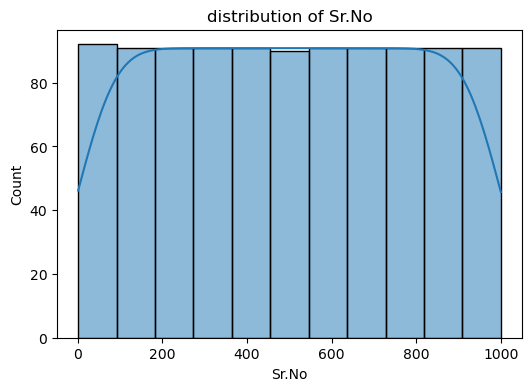

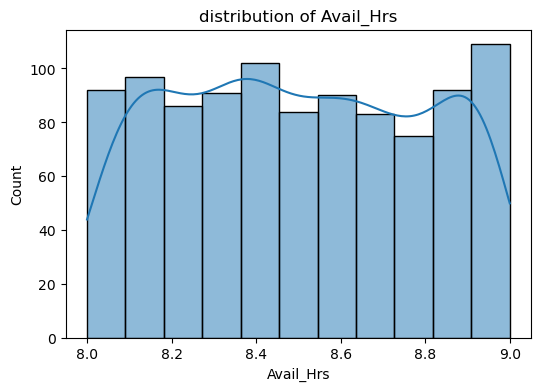

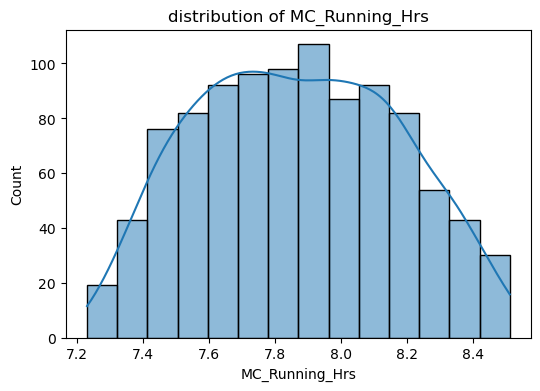

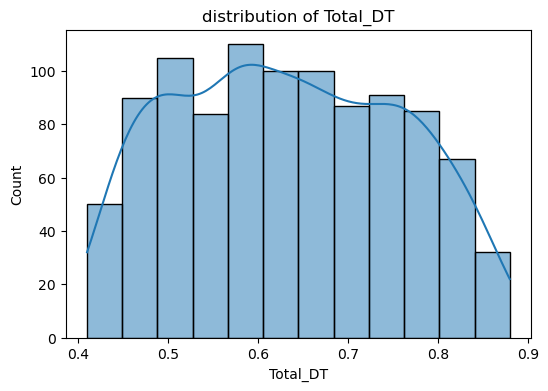

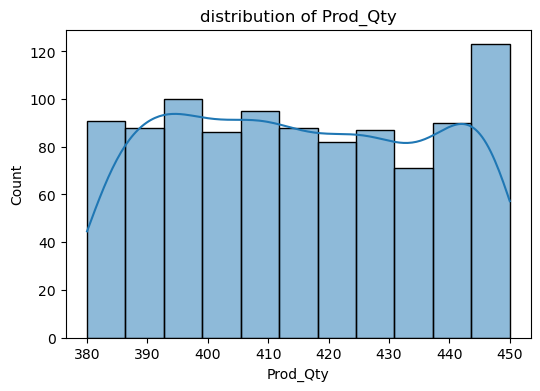

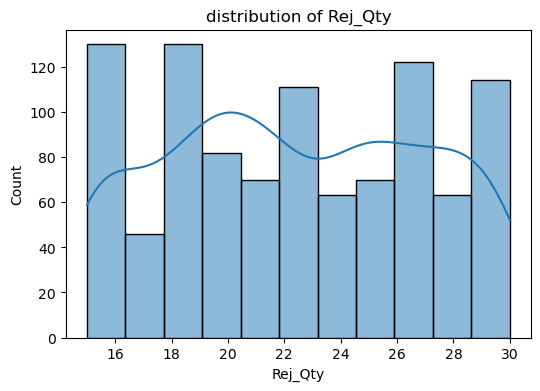

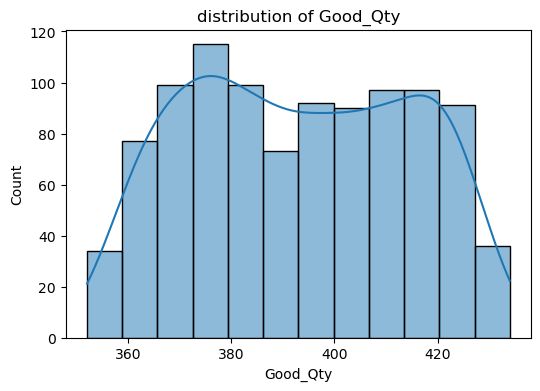

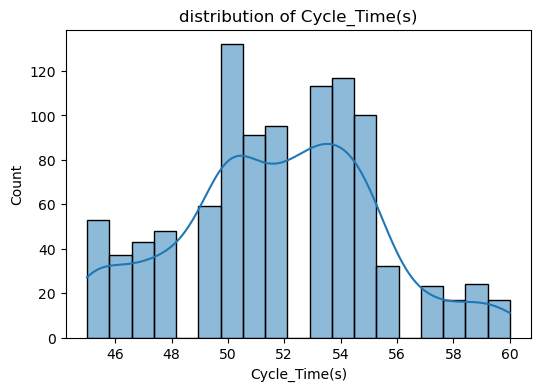

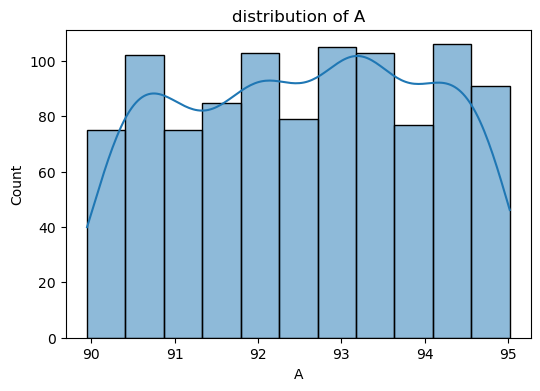

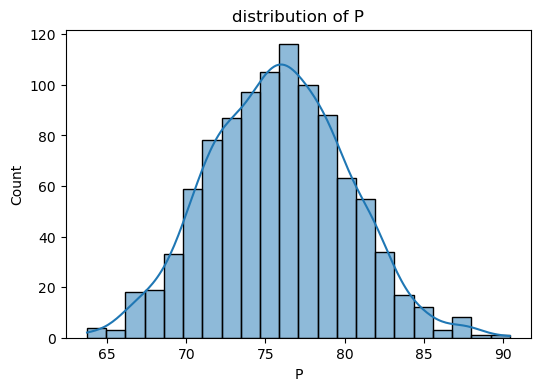

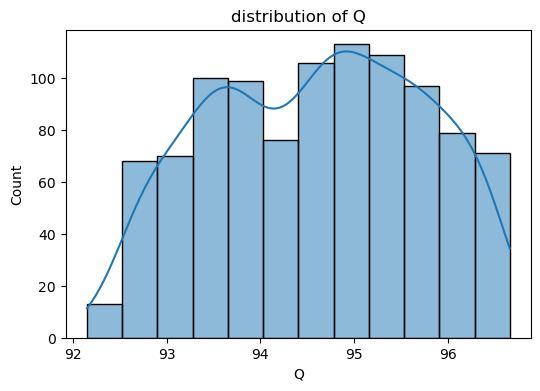

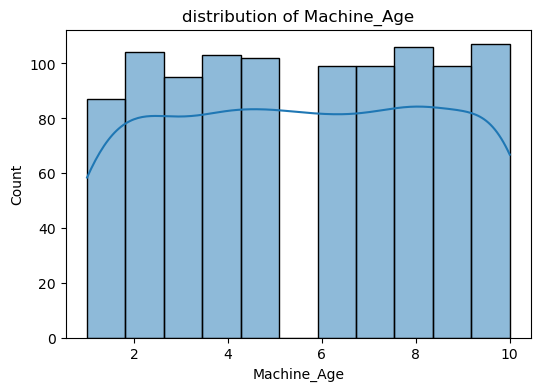

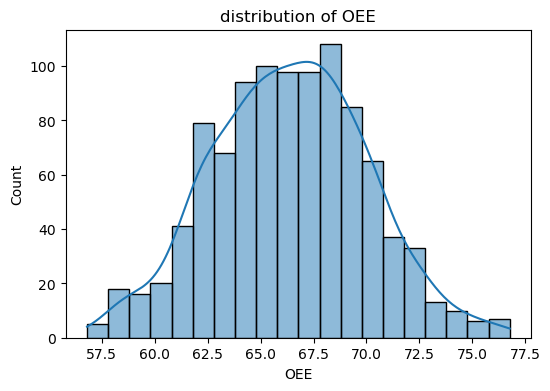

In [14]:
#for all feature 
num_col = df.select_dtypes(include="number").columns
for col in num_col:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col],kde = True)
    plt.title(f"distribution of {col}")
    plt.show()

##### -> Visualization of correlation matix

<Axes: >

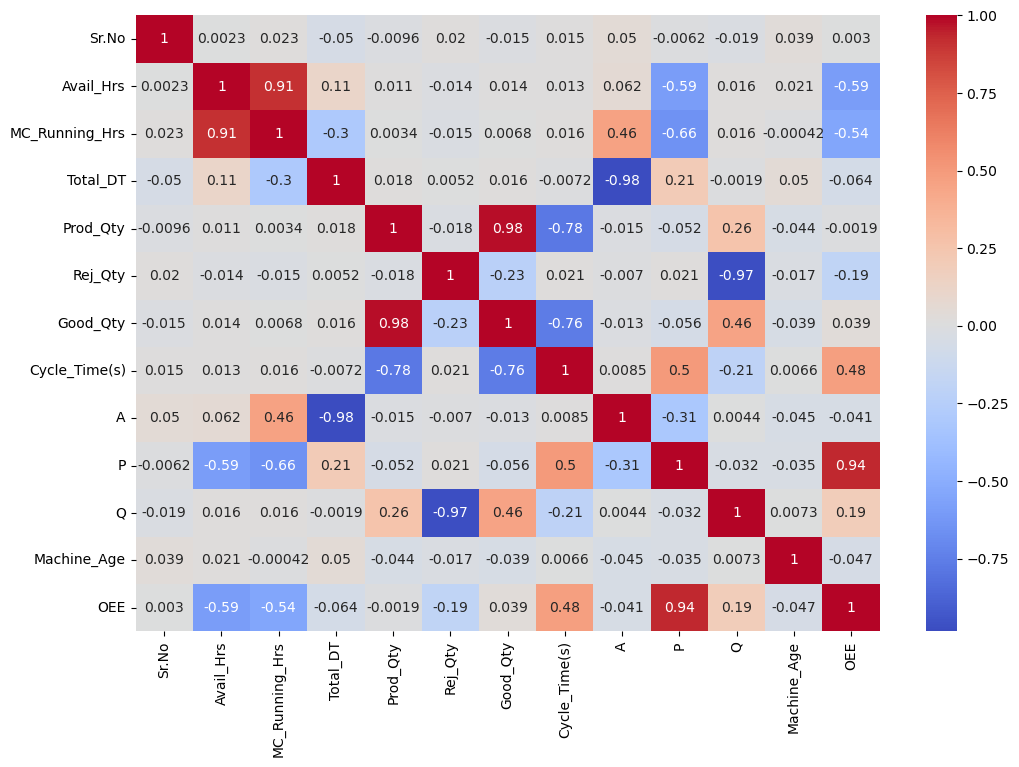

In [25]:
plt.figure(figsize=(12,8))
sns.heatmap(df_num.corr(),annot=True,cmap = "coolwarm")

##### ->Pairplot - Visualize relationships between multiple variables at once

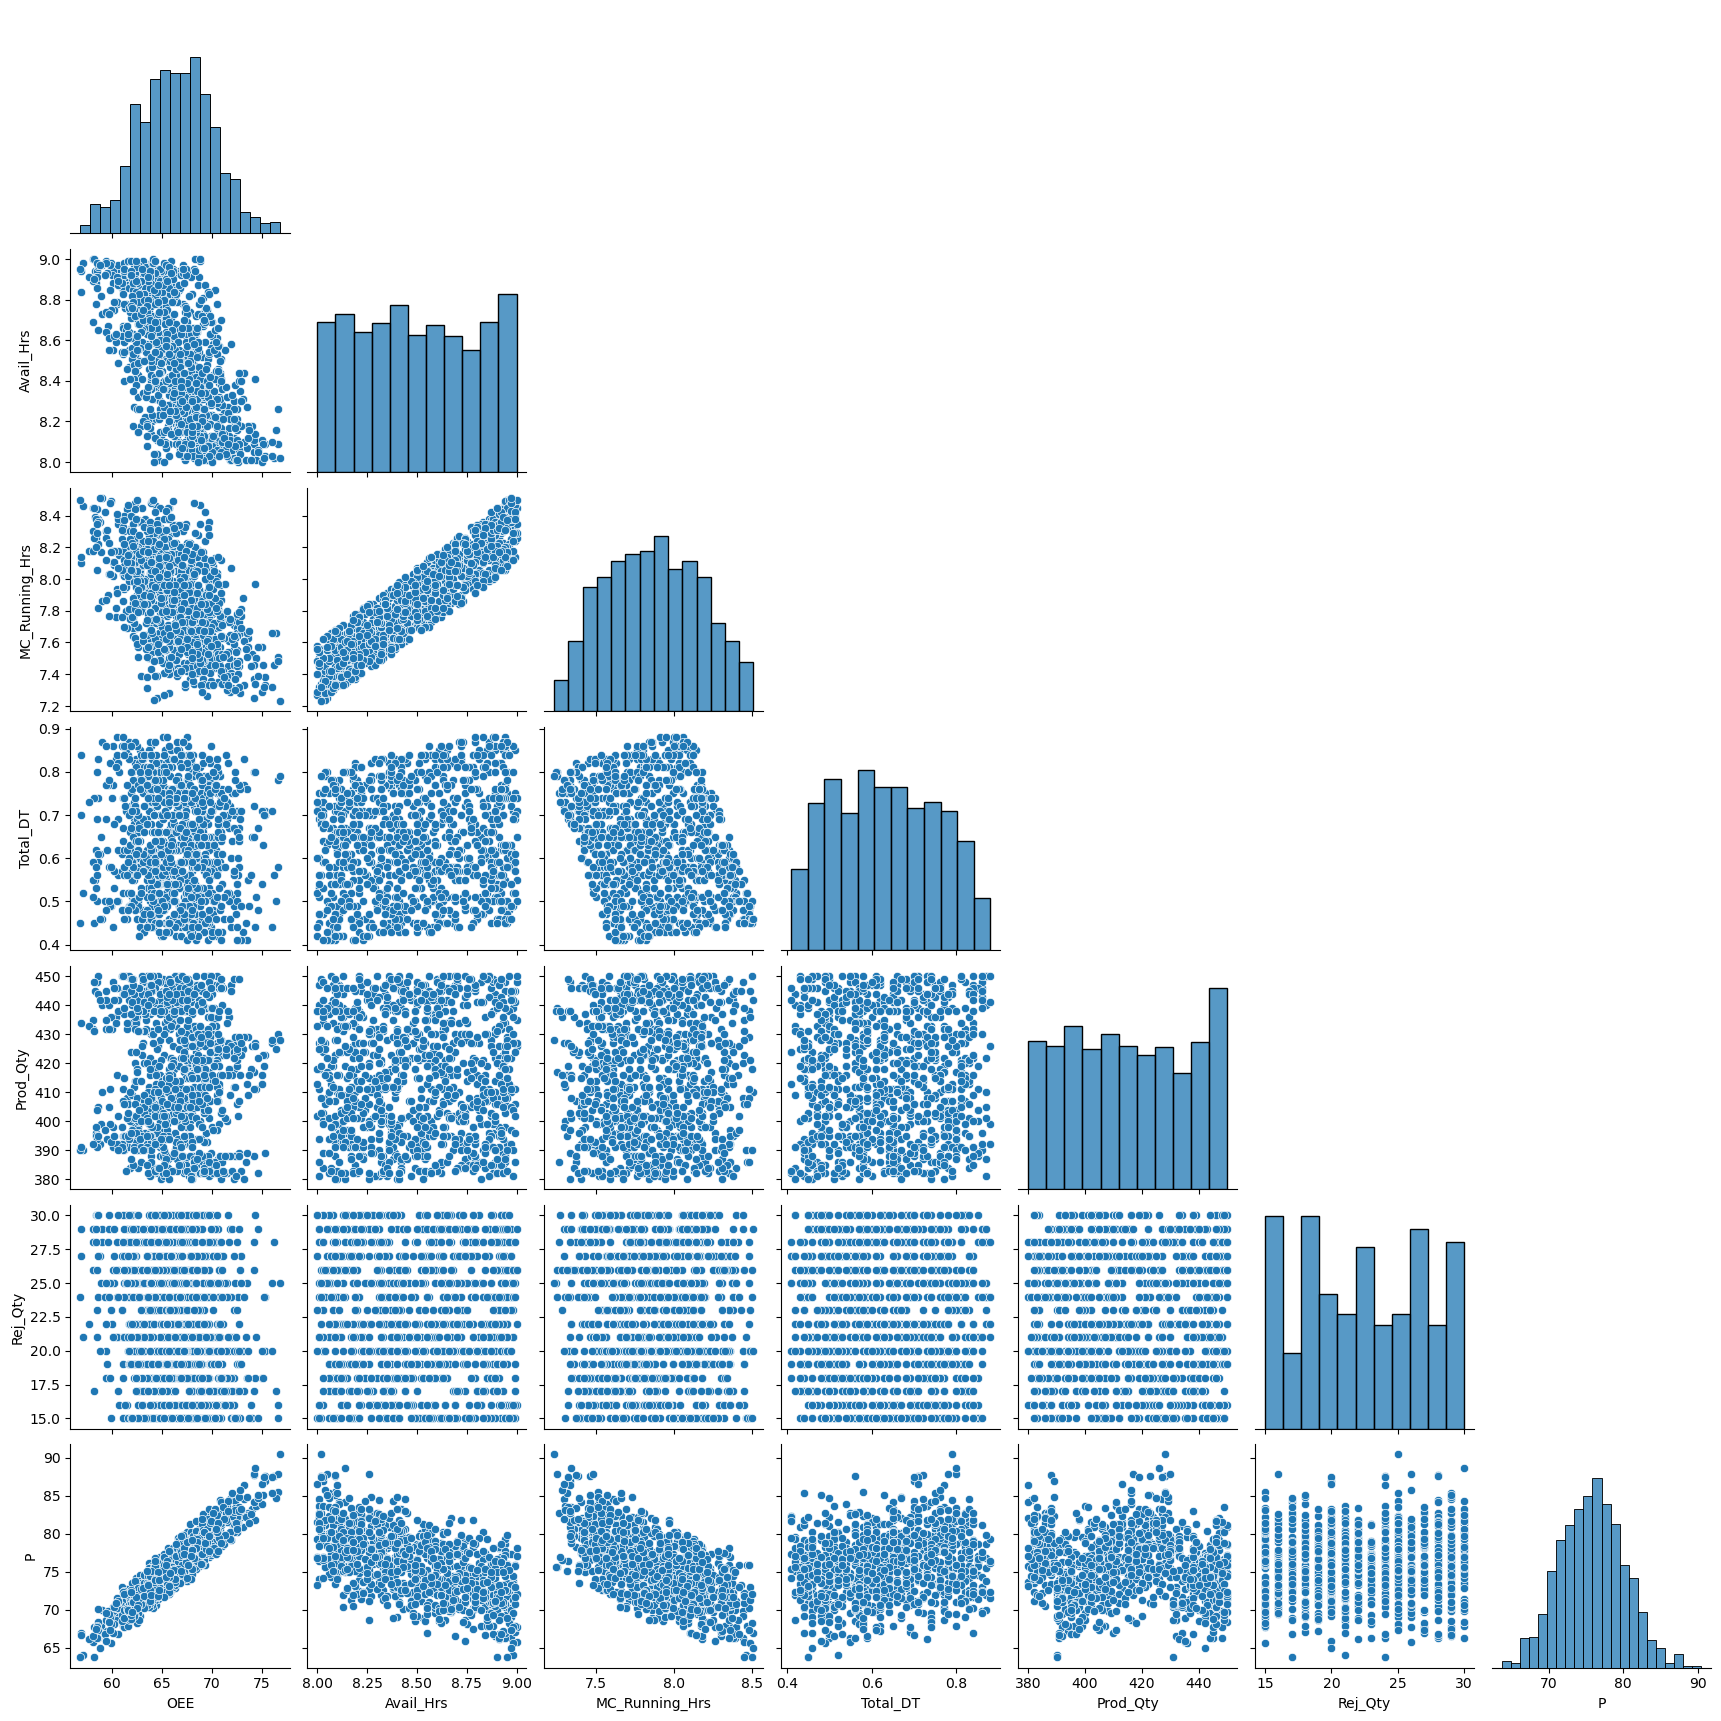

In [15]:
pairplot_cols = ["OEE", "Avail_Hrs", "MC_Running_Hrs", "Total_DT", "Prod_Qty", "Rej_Qty", "P"]
sns.pairplot(df[pairplot_cols].dropna(), corner=True)
plt.show()

##### -> Distribution of OEE values → The KDE plot shows how the values of OEE are spread out.

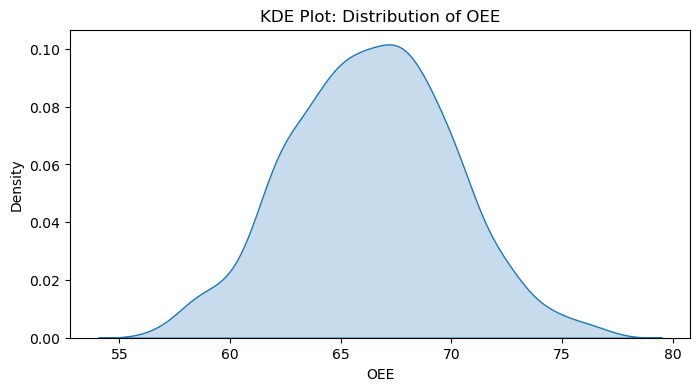

In [16]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df["OEE"], fill=True)
plt.title("KDE Plot: Distribution of OEE")
plt.show()

#### -> Checked the skewness of all numeric columns

In [17]:
df.skew(numeric_only=True)

Sr.No             0.000102
Avail_Hrs         0.033878
MC_Running_Hrs    0.070193
Total_DT          0.085171
Prod_Qty          0.037047
Rej_Qty           0.018854
Good_Qty          0.023412
Cycle_Time(s)     0.014897
A                -0.058002
P                 0.088976
Q                -0.085923
Machine_Age      -0.021417
OEE               0.036131
dtype: float64

In [ ]:
What skewness tells us:

Skewness measures asymmetry of the distribution of values in a column.

A perfectly symmetric distribution (like a normal distribution) has skewness ≈ 0.

Positive skew → long tail on the right (more small values, few very large ones).

Negative skew → long tail on the left (more large values, few very small ones).

In [ ]:
observation about skewness 

Most of columns (like Avail_Hrs, Prod_Qty, OEE) have skewness values close to 0, meaning their distributions are fairly symmetric.

Some columns (A, Q, Machine_Age) show small negative skew, while others (P, Total_DT) show small positive skew.

None of the skewness values are extreme, so dataset looks quite balanced without heavy tails.

#### ->box plot - (Graphical method to check the outliers)

In [ ]:
outlier detection visualization for all numeric columns

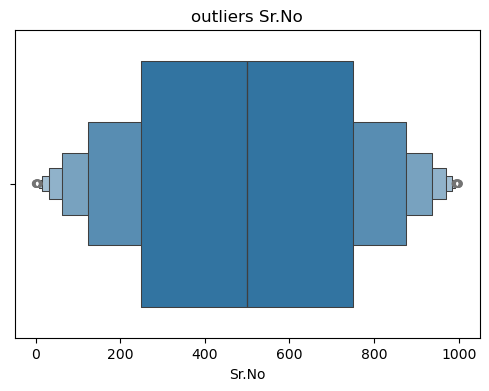

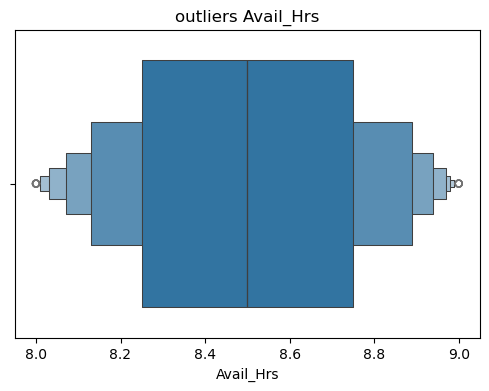

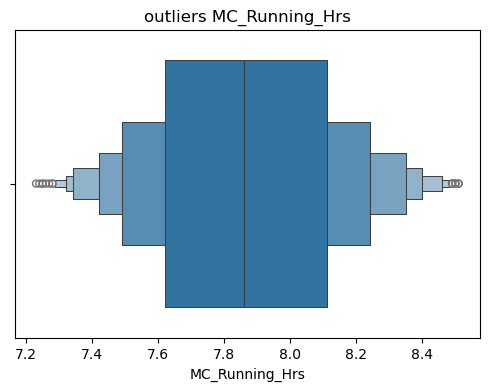

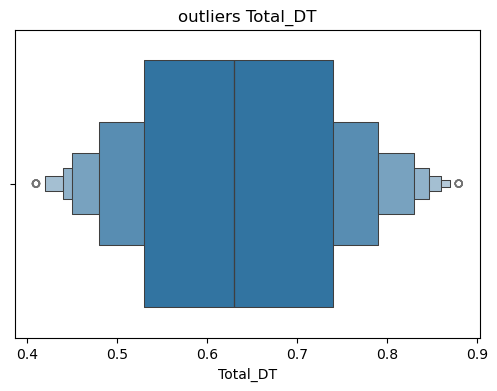

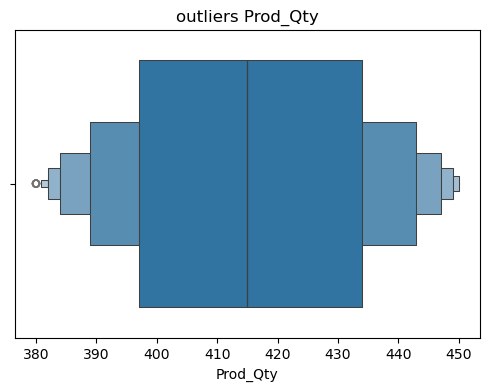

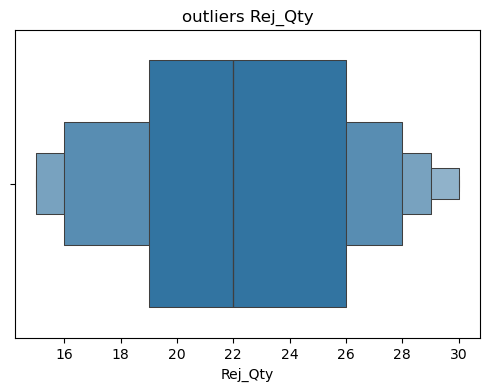

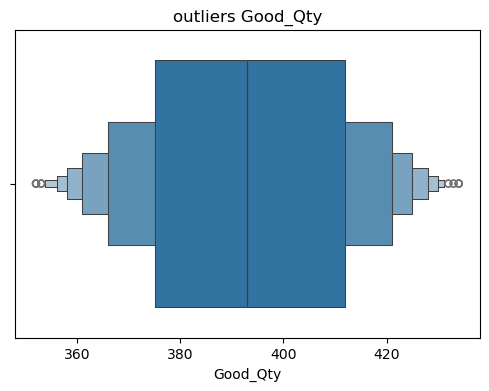

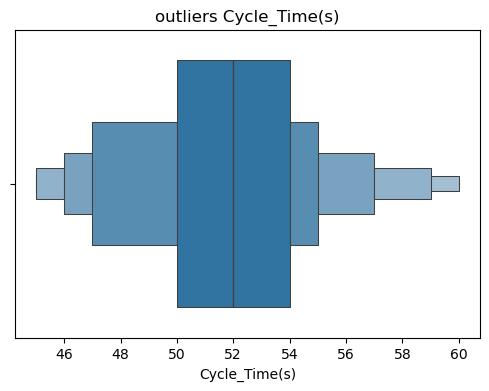

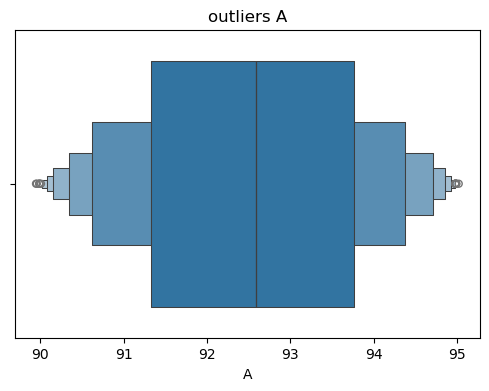

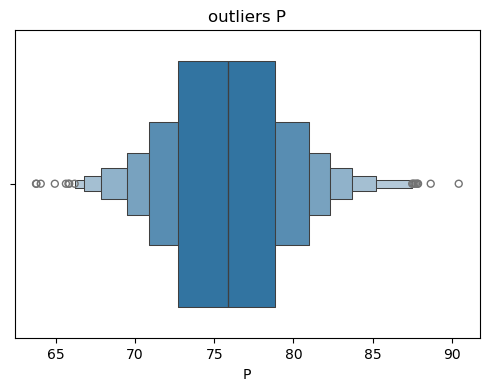

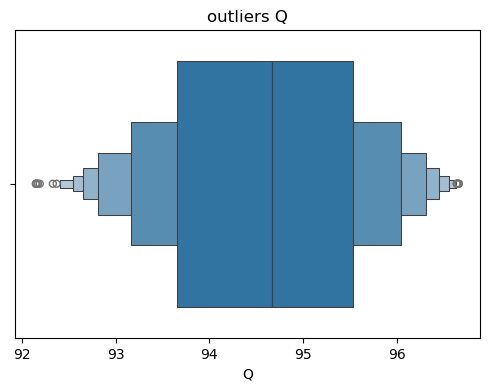

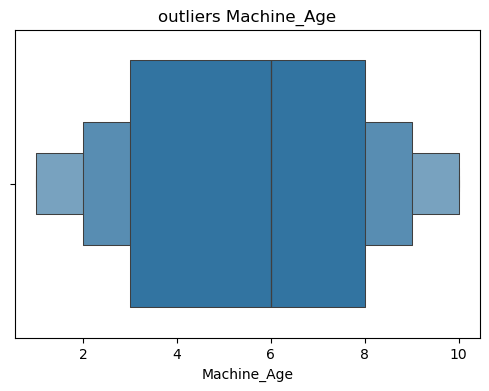

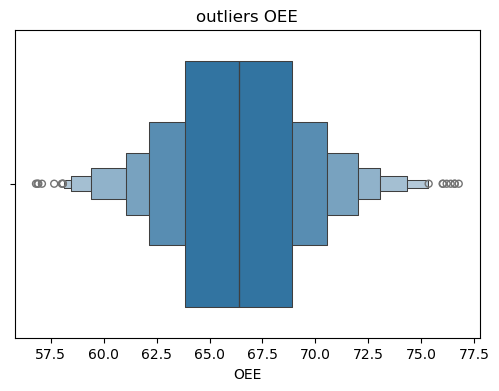

In [18]:
df_num = df.select_dtypes(include = "number").columns 
for col in df_num:
    plt.figure(figsize=(6,4))
    sns.boxenplot(x = df[col])
    plt.title(f"outliers {col}")
    plt.show()

In [ ]:
#another way to check box plot (all columns are come into one place)
#but its not visible properly so we need to scale down 

<Axes: >

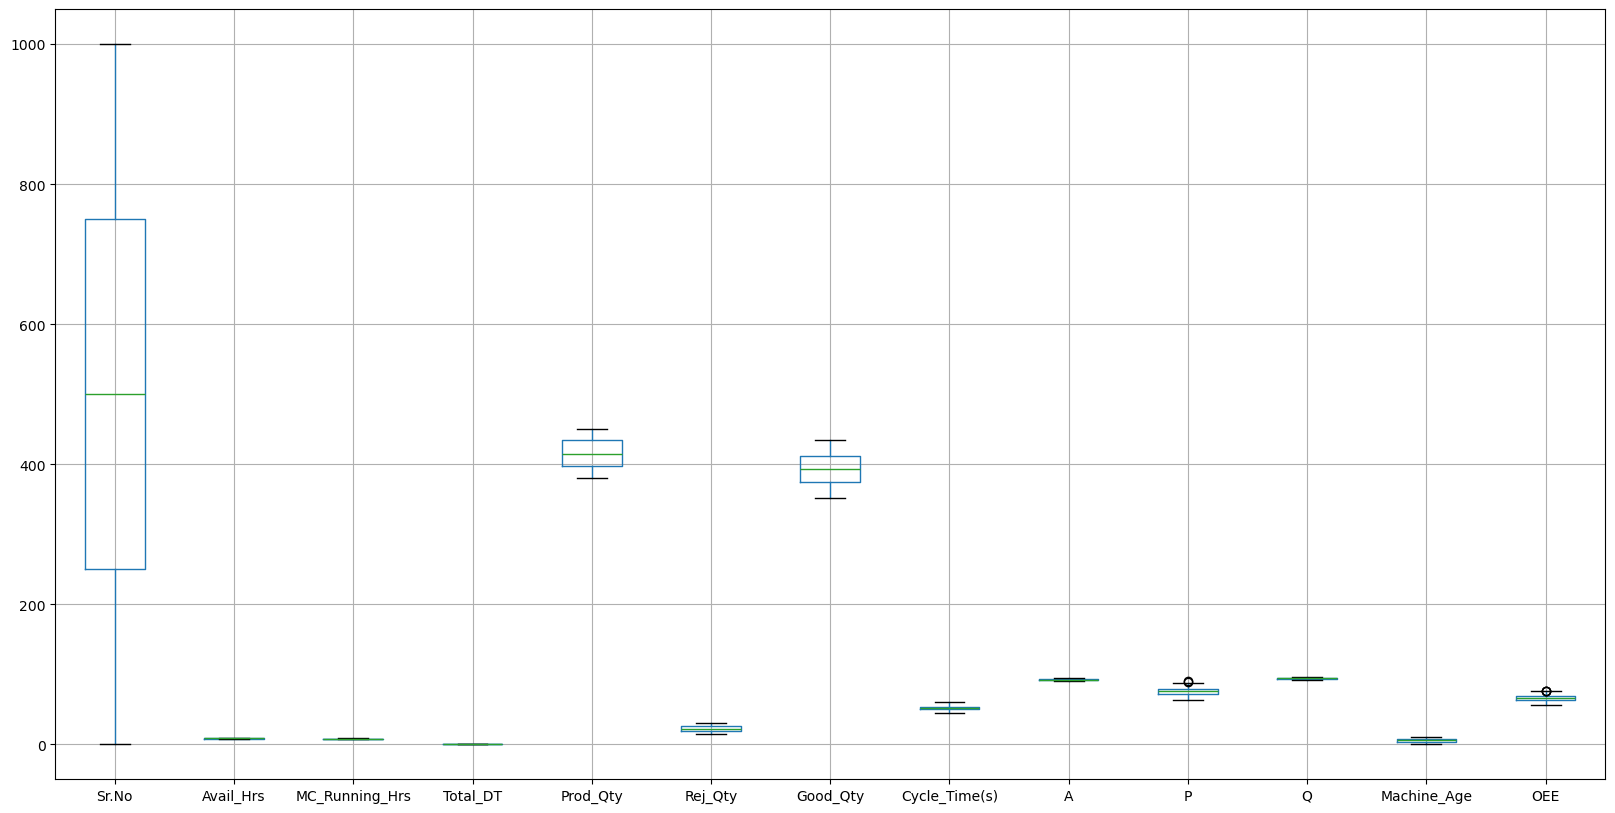

In [30]:
df[num_col].boxplot(figsize=(20,10))

#### OEE is the individual target box plot.

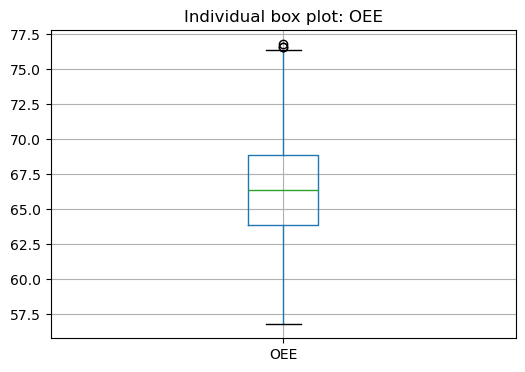

In [31]:
df[["OEE"]].boxplot(figsize=(6, 4))
plt.title("Individual box plot: OEE")
plt.show()

#### ->check outliers - scatter plot `

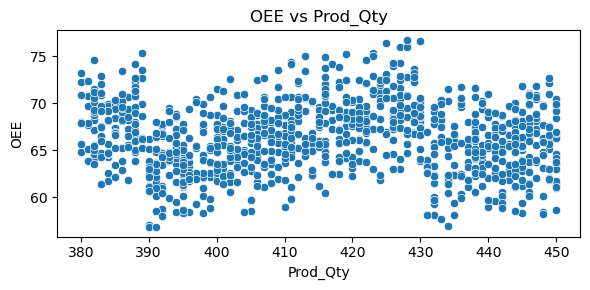

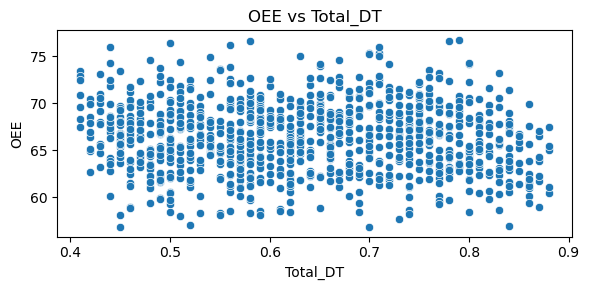

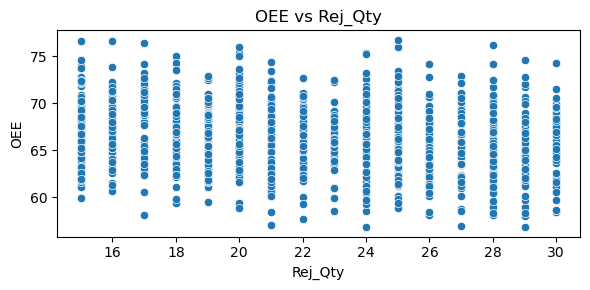

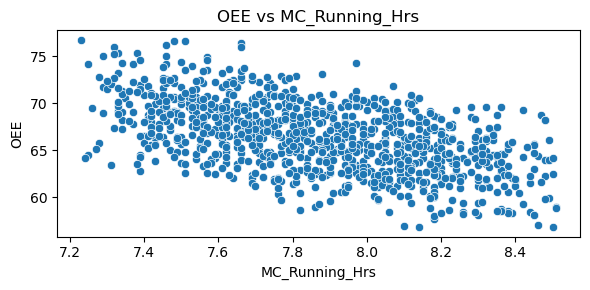

In [19]:
for col in ["Prod_Qty","Total_DT", "Rej_Qty", "MC_Running_Hrs"]:
    plt.figure(figsize=(6, 3))
    sns.scatterplot(data=df, x=col, y="OEE")
    plt.title(f"OEE vs {col}")
    plt.tight_layout()
    plt.show()

Total_DT
Boxplot showed variability and possible long tails.
Skewness ≈ 0.085 (positive skew).

MC_Running_Hrs
Boxplot showed spread with possible mild outliers.
Skewness ≈ 0.07 (slight skew).


Rej_Qty
Boxplot showed scattered values.
Skewness ≈ 0.018 (almost symmetric, but rejection counts often produce outliers).

#### ->Check outlier by statistical method -shapiro test

In [33]:
from scipy.stats import shapiro
stat, p_value = shapiro (df["OEE"])
if p_value  > 0.05:
    print ("data is normaly distributed")
else:
    print ("data is not normally distributed")

data is normaly distributed


In [34]:
from scipy.stats import shapiro
stat, p_value = shapiro (df["P"])
if p_value > 0.05:
    print ("data is normaly distributed")
else:
    print ("data is not normally distributed")

data is normaly distributed


In [35]:
from scipy.stats import shapiro
stat, p_value = shapiro (df["Total_DT"])
if p_value > 0.05:
    print ("data is normaly distributed")
else:
    print ("data is not normally distributed")

data is not normally distributed


In [36]:
from scipy.stats import shapiro
stat, p_value = shapiro (df["MC_Running_Hrs"])
if p_value > 0.05:
    print ("data is normaly distributed")
else:
    print ("data is not normally distributed")

data is not normally distributed


In [37]:
from scipy.stats import shapiro
stat, p_value = shapiro (df["Rej_Qty"])
if p_value > 0.05:
    print ("data is normaly distributed")
else:
    print ("data is not normally distributed")

data is not normally distributed


In [38]:
# Shapiro normality test (use a maximum 500-row sample).
for col in ["OEE", "P", "Total_DT", "MC_Running_Hrs", "Rej_Qty"]:
    sample = df[col].dropna().sample(min(500, df[col].notna().sum()), random_state=42)
    _, p_value = shapiro(sample)
    print(f"Shapiro test: {col}, p-value = {p_value:.4f}")

Shapiro test: OEE, p-value = 0.3451
Shapiro test: P, p-value = 0.9304
Shapiro test: Total_DT, p-value = 0.0000
Shapiro test: MC_Running_Hrs, p-value = 0.0000
Shapiro test: Rej_Qty, p-value = 0.0000


##### -> Check outlier by statistical method - iqr method 

In [39]:
q1 = np.quantile(df["OEE"],0.25)
q2 = np.quantile(df["OEE"],0.5)
q3 = np.quantile(df["OEE"],0.75)
iqr = q3 - q1 
upper_tail = q3 + 1.5*iqr
lower_tail = q1 - 1.5*iqr
outlier_index = np.where ((df["OEE"] > upper_tail) | (df["OEE"] < lower_tail))
outlier_index

(array([202, 652, 913]),)

In [40]:
q1 = np.quantile(df["P"],0.25)
q2 = np.quantile(df["P"],0.5)
q3 = np.quantile(df["P"],0.75)
iqr = q3 - q1 
upper_tail = q3 + 1.5*iqr
lower_tail = q1 - 1.5*iqr
outlier_index = np.where ((df["P"] > upper_tail) | (df["P"] < lower_tail))
outlier_index

(array([898, 913]),)

In [41]:
q1 = np.quantile(df["Total_DT"],0.25)
q2 = np.quantile(df["Total_DT"],0.5)
q3 = np.quantile(df["Total_DT"],0.75)
iqr = q3 - q1 
upper_tail = q3 + 1.5*iqr
lower_tail = q1 - 1.5*iqr
outlier_index = np.where ((df["Total_DT"] > upper_tail) | (df["Total_DT"] < lower_tail))
outlier_index

(array([], dtype=int64),)

In [42]:
q1 = np.quantile(df["MC_Running_Hrs"],0.25)
q2 = np.quantile(df["MC_Running_Hrs"],0.5)
q3 = np.quantile(df["MC_Running_Hrs"],0.75)
iqr = q3 - q1 
upper_tail = q3 + 1.5*iqr
lower_tail = q1 - 1.5*iqr
outlier_index = np.where ((df["MC_Running_Hrs"] > upper_tail) | (df["MC_Running_Hrs"] < lower_tail))
outlier_index

(array([], dtype=int64),)

In [43]:
q1 = np.quantile(df["Rej_Qty"],0.25)
q2 = np.quantile(df["Rej_Qty"],0.5)
q3 = np.quantile(df["Rej_Qty"],0.75)
iqr = q3 - q1 
upper_tail = q3 + 1.5*iqr
lower_tail = q1 - 1.5*iqr
outlier_index = np.where ((df["Rej_Qty"] > upper_tail) | (df["Rej_Qty"] < lower_tail))
outlier_index

(array([], dtype=int64),)

##### ->Check outlier by z score method

In [44]:
from scipy import stats

z_score = np.abs(stats.zscore(df["OEE"]))
threshold = 3
outlier_index = np.where(z_score > threshold)
outlier_lst = df["OEE"].iloc[outlier_index]
print("Outliers in OEE:", outlier_lst.values)

Outliers in OEE: []


In [45]:
from scipy import stats

z_score = np.abs(stats.zscore(df["P"]))
threshold = 3
outlier_index = np.where(z_score > threshold)
outlier_lst = df["P"].iloc[outlier_index]
print("Outliers in P:", outlier_lst.values)

Outliers in P: [90.44]


In [46]:
from scipy import stats

z_score = np.abs(stats.zscore(df["Total_DT"]))
threshold = 3
outlier_index = np.where(z_score > threshold)
outlier_lst = df["Total_DT"].iloc[outlier_index]
print("Outliers in Total_DT:", outlier_lst.values)

Outliers in Total_DT: []


In [47]:
from scipy import stats

z_score = np.abs(stats.zscore(df["MC_Running_Hrs"]))
threshold = 3
outlier_index = np.where(z_score > threshold)
outlier_lst = df["MC_Running_Hrs"].iloc[outlier_index]
print("Outliers in MC_Running_Hrs:", outlier_lst.values)

Outliers in MC_Running_Hrs: []


In [48]:
from scipy import stats

z_score = np.abs(stats.zscore(df["Rej_Qty"]))
threshold = 3
outlier_index = np.where(z_score > threshold)
outlier_lst = df["Rej_Qty"].iloc[outlier_index]
print("Outliers in Rej_Qty:", outlier_lst.values)

Outliers in Rej_Qty: []


### Feature Engineering 

##### --> copy datframe for feature engineering 

In [20]:
df1 = df.copy()
df1.head()

,Sr.No,Machine_No,Date,Shift,Customer,Part_Name,Avail_Hrs,MC_Running_Hrs,Total_DT,Prod_Qty,Rej_Qty,Good_Qty,Cycle_Time(s),A,P,Q,Machine_Age,Operator_Team,Maintenance_Flag,OEE
0,1,FERROMATIC(3),01-08-2026,A,NaN,Gearbox,8.11,7.46,0.65,447,15,432.0,46,91.99,76.56,96.64,3,Team-3,Yes,68.06
1,2,FERROMATIC(4),01-08-2026,B,Tata,Sunroof,8.58,8.08,0.50,437,18,419.0,47,94.17,70.61,95.88,10,Team-3,No,63.75
2,3,FERROMATIC(1),01-08-2026,A,Mahindra,Gearbox,8.43,7.94,0.49,401,21,NaN,50,94.19,70.14,94.76,5,Team-2,Yes,62.60
3,4,FERROMATIC(1),01-08-2026,B,Mahindra,Panel,8.42,7.86,0.56,439,18,421.0,50,93.35,77.57,95.90,3,Team-1,NaN,69.44
4,5,FERROMATIC(3),01-08-2026,B,Tata,Gearbox,8.27,7.48,0.79,412,15,397.0,53,90.45,81.09,96.36,6,Team-2,Yes,70.68


##### -->Converted the Date column from string/text format to a proper datetime format.

In [21]:
df1["Date"] = pd.to_datetime(df1["Date"], format="%d-%m-%Y")
df1.head()

,Sr.No,Machine_No,Date,Shift,Customer,Part_Name,Avail_Hrs,MC_Running_Hrs,Total_DT,Prod_Qty,Rej_Qty,Good_Qty,Cycle_Time(s),A,P,Q,Machine_Age,Operator_Team,Maintenance_Flag,OEE
0,1,FERROMATIC(3),2026-08-01,A,NaN,Gearbox,8.11,7.46,0.65,447,15,432.0,46,91.99,76.56,96.64,3,Team-3,Yes,68.06
1,2,FERROMATIC(4),2026-08-01,B,Tata,Sunroof,8.58,8.08,0.50,437,18,419.0,47,94.17,70.61,95.88,10,Team-3,No,63.75
2,3,FERROMATIC(1),2026-08-01,A,Mahindra,Gearbox,8.43,7.94,0.49,401,21,NaN,50,94.19,70.14,94.76,5,Team-2,Yes,62.60
3,4,FERROMATIC(1),2026-08-01,B,Mahindra,Panel,8.42,7.86,0.56,439,18,421.0,50,93.35,77.57,95.90,3,Team-1,NaN,69.44
4,5,FERROMATIC(3),2026-08-01,B,Tata,Gearbox,8.27,7.48,0.79,412,15,397.0,53,90.45,81.09,96.36,6,Team-2,Yes,70.68


##### -->Filling missing values

In [22]:
df1["Customer"] = df1["Customer"].fillna(df1["Customer"].mode()[0])
df1.head()

,Sr.No,Machine_No,Date,Shift,Customer,Part_Name,Avail_Hrs,MC_Running_Hrs,Total_DT,Prod_Qty,Rej_Qty,Good_Qty,Cycle_Time(s),A,P,Q,Machine_Age,Operator_Team,Maintenance_Flag,OEE
0,1,FERROMATIC(3),2026-08-01,A,Grupo,Gearbox,8.11,7.46,0.65,447,15,432.0,46,91.99,76.56,96.64,3,Team-3,Yes,68.06
1,2,FERROMATIC(4),2026-08-01,B,Tata,Sunroof,8.58,8.08,0.50,437,18,419.0,47,94.17,70.61,95.88,10,Team-3,No,63.75
2,3,FERROMATIC(1),2026-08-01,A,Mahindra,Gearbox,8.43,7.94,0.49,401,21,NaN,50,94.19,70.14,94.76,5,Team-2,Yes,62.60
3,4,FERROMATIC(1),2026-08-01,B,Mahindra,Panel,8.42,7.86,0.56,439,18,421.0,50,93.35,77.57,95.90,3,Team-1,NaN,69.44
4,5,FERROMATIC(3),2026-08-01,B,Tata,Gearbox,8.27,7.48,0.79,412,15,397.0,53,90.45,81.09,96.36,6,Team-2,Yes,70.68


In [23]:
df1["Maintenance_Flag"] = df1["Maintenance_Flag"].fillna(df1["Maintenance_Flag"].mode()[0])
df1.head()

,Sr.No,Machine_No,Date,Shift,Customer,Part_Name,Avail_Hrs,MC_Running_Hrs,Total_DT,Prod_Qty,Rej_Qty,Good_Qty,Cycle_Time(s),A,P,Q,Machine_Age,Operator_Team,Maintenance_Flag,OEE
0,1,FERROMATIC(3),2026-08-01,A,Grupo,Gearbox,8.11,7.46,0.65,447,15,432.0,46,91.99,76.56,96.64,3,Team-3,Yes,68.06
1,2,FERROMATIC(4),2026-08-01,B,Tata,Sunroof,8.58,8.08,0.50,437,18,419.0,47,94.17,70.61,95.88,10,Team-3,No,63.75
2,3,FERROMATIC(1),2026-08-01,A,Mahindra,Gearbox,8.43,7.94,0.49,401,21,NaN,50,94.19,70.14,94.76,5,Team-2,Yes,62.60
3,4,FERROMATIC(1),2026-08-01,B,Mahindra,Panel,8.42,7.86,0.56,439,18,421.0,50,93.35,77.57,95.90,3,Team-1,No,69.44
4,5,FERROMATIC(3),2026-08-01,B,Tata,Gearbox,8.27,7.48,0.79,412,15,397.0,53,90.45,81.09,96.36,6,Team-2,Yes,70.68


In [24]:
df1["Good_Qty"] = df1["Prod_Qty"] - df1["Rej_Qty"]
df1.head()

,Sr.No,Machine_No,Date,Shift,Customer,Part_Name,Avail_Hrs,MC_Running_Hrs,Total_DT,Prod_Qty,Rej_Qty,Good_Qty,Cycle_Time(s),A,P,Q,Machine_Age,Operator_Team,Maintenance_Flag,OEE
0,1,FERROMATIC(3),2026-08-01,A,Grupo,Gearbox,8.11,7.46,0.65,447,15,432,46,91.99,76.56,96.64,3,Team-3,Yes,68.06
1,2,FERROMATIC(4),2026-08-01,B,Tata,Sunroof,8.58,8.08,0.50,437,18,419,47,94.17,70.61,95.88,10,Team-3,No,63.75
2,3,FERROMATIC(1),2026-08-01,A,Mahindra,Gearbox,8.43,7.94,0.49,401,21,380,50,94.19,70.14,94.76,5,Team-2,Yes,62.60
3,4,FERROMATIC(1),2026-08-01,B,Mahindra,Panel,8.42,7.86,0.56,439,18,421,50,93.35,77.57,95.90,3,Team-1,No,69.44
4,5,FERROMATIC(3),2026-08-01,B,Tata,Gearbox,8.27,7.48,0.79,412,15,397,53,90.45,81.09,96.36,6,Team-2,Yes,70.68


In [25]:
df1.isna().sum() #checked missing value after fill missed values 

Sr.No               0
Machine_No          0
Date                0
Shift               0
Customer            0
Part_Name           0
Avail_Hrs           0
MC_Running_Hrs      0
Total_DT            0
Prod_Qty            0
Rej_Qty             0
Good_Qty            0
Cycle_Time(s)       0
A                   0
P                   0
Q                   0
Machine_Age         0
Operator_Team       0
Maintenance_Flag    0
OEE                 0
dtype: int64

##### -->remove duplicates record

In [26]:
df1.drop_duplicates(inplace=True)
df1.head(5)

,Sr.No,Machine_No,Date,Shift,Customer,Part_Name,Avail_Hrs,MC_Running_Hrs,Total_DT,Prod_Qty,Rej_Qty,Good_Qty,Cycle_Time(s),A,P,Q,Machine_Age,Operator_Team,Maintenance_Flag,OEE
0,1,FERROMATIC(3),2026-08-01,A,Grupo,Gearbox,8.11,7.46,0.65,447,15,432,46,91.99,76.56,96.64,3,Team-3,Yes,68.06
1,2,FERROMATIC(4),2026-08-01,B,Tata,Sunroof,8.58,8.08,0.50,437,18,419,47,94.17,70.61,95.88,10,Team-3,No,63.75
2,3,FERROMATIC(1),2026-08-01,A,Mahindra,Gearbox,8.43,7.94,0.49,401,21,380,50,94.19,70.14,94.76,5,Team-2,Yes,62.60
3,4,FERROMATIC(1),2026-08-01,B,Mahindra,Panel,8.42,7.86,0.56,439,18,421,50,93.35,77.57,95.90,3,Team-1,No,69.44
4,5,FERROMATIC(3),2026-08-01,B,Tata,Gearbox,8.27,7.48,0.79,412,15,397,53,90.45,81.09,96.36,6,Team-2,Yes,70.68


In [27]:
df1.head()

,Sr.No,Machine_No,Date,Shift,Customer,Part_Name,Avail_Hrs,MC_Running_Hrs,Total_DT,Prod_Qty,Rej_Qty,Good_Qty,Cycle_Time(s),A,P,Q,Machine_Age,Operator_Team,Maintenance_Flag,OEE
0,1,FERROMATIC(3),2026-08-01,A,Grupo,Gearbox,8.11,7.46,0.65,447,15,432,46,91.99,76.56,96.64,3,Team-3,Yes,68.06
1,2,FERROMATIC(4),2026-08-01,B,Tata,Sunroof,8.58,8.08,0.50,437,18,419,47,94.17,70.61,95.88,10,Team-3,No,63.75
2,3,FERROMATIC(1),2026-08-01,A,Mahindra,Gearbox,8.43,7.94,0.49,401,21,380,50,94.19,70.14,94.76,5,Team-2,Yes,62.60
3,4,FERROMATIC(1),2026-08-01,B,Mahindra,Panel,8.42,7.86,0.56,439,18,421,50,93.35,77.57,95.90,3,Team-1,No,69.44
4,5,FERROMATIC(3),2026-08-01,B,Tata,Gearbox,8.27,7.48,0.79,412,15,397,53,90.45,81.09,96.36,6,Team-2,Yes,70.68


##### --> Convert maintnencne flag (Encoding)

In [28]:
df1["Maintenance_Flag"] = (df1["Maintenance_Flag"].map({"Yes": 1,"No": 0}))
df1.head()

,Sr.No,Machine_No,Date,Shift,Customer,Part_Name,Avail_Hrs,MC_Running_Hrs,Total_DT,Prod_Qty,Rej_Qty,Good_Qty,Cycle_Time(s),A,P,Q,Machine_Age,Operator_Team,Maintenance_Flag,OEE
0,1,FERROMATIC(3),2026-08-01,A,Grupo,Gearbox,8.11,7.46,0.65,447,15,432,46,91.99,76.56,96.64,3,Team-3,1,68.06
1,2,FERROMATIC(4),2026-08-01,B,Tata,Sunroof,8.58,8.08,0.50,437,18,419,47,94.17,70.61,95.88,10,Team-3,0,63.75
2,3,FERROMATIC(1),2026-08-01,A,Mahindra,Gearbox,8.43,7.94,0.49,401,21,380,50,94.19,70.14,94.76,5,Team-2,1,62.60
3,4,FERROMATIC(1),2026-08-01,B,Mahindra,Panel,8.42,7.86,0.56,439,18,421,50,93.35,77.57,95.90,3,Team-1,0,69.44
4,5,FERROMATIC(3),2026-08-01,B,Tata,Gearbox,8.27,7.48,0.79,412,15,397,53,90.45,81.09,96.36,6,Team-2,1,70.68


##### --> Create Daily machine data 

In [29]:
# The raw dataset has multiple records/shifts per machine per day.
# The prediction target is daily OEE, so first aggregate to:
# one row = one machine on one date.

daily = (
    df1.groupby(
        ["Date", "Machine_No"],
        as_index=False
    )
    .agg({
        "OEE": "mean",
        "Avail_Hrs": "mean",
        "MC_Running_Hrs": "mean",
        "Total_DT": "mean",
        "Prod_Qty": "sum",
        "Rej_Qty": "sum",
        "Machine_Age": "first",
        "Maintenance_Flag": "first",
    })
)
daily.head()

,Date,Machine_No,OEE,Avail_Hrs,MC_Running_Hrs,Total_DT,Prod_Qty,Rej_Qty,Machine_Age,Maintenance_Flag
0,2026-08-01,FERROMATIC(1),66.510000,8.382857,7.795714,0.587143,2873,143,5,1
1,2026-08-01,FERROMATIC(2),66.290000,8.478000,7.860000,0.618000,4160,236,9,0
2,2026-08-01,FERROMATIC(3),66.553636,8.483636,7.829091,0.654545,4670,252,3,1
3,2026-08-01,FERROMATIC(4),66.790833,8.536667,7.887500,0.649167,5010,284,10,0
4,2026-08-01,FERROMATIC(5),66.387000,8.449000,7.835000,0.614000,4167,226,10,1


##### --> Observation fix --> Sort before creating Lags 

In [30]:
# A lag means "the previous chronological record for the same
# machine". Therefore the data MUST be sorted by Machine_No and Date
# before groupby().shift(1).
# This is the most important correction to the original notebook.

daily = daily.sort_values(["Machine_No", "Date"]).reset_index(drop=True)

print("\nDaily dataset shape:", daily.shape)
daily.head()


Daily dataset shape: (110, 10)


,Date,Machine_No,OEE,Avail_Hrs,MC_Running_Hrs,Total_DT,Prod_Qty,Rej_Qty,Machine_Age,Maintenance_Flag
0,2026-08-01,FERROMATIC(1),66.510000,8.382857,7.795714,0.587143,2873,143,5,1
1,2026-08-02,FERROMATIC(1),65.562500,8.437500,7.789167,0.648333,4882,271,6,1
2,2026-08-03,FERROMATIC(1),65.244444,8.647778,7.998889,0.648889,3858,188,7,1
3,2026-08-04,FERROMATIC(1),64.978182,8.618182,7.959091,0.659091,4548,229,8,1
4,2026-08-05,FERROMATIC(1),66.960000,8.405556,7.822222,0.583333,3778,192,9,0


### Time Series Stationarity Check

Stationarity is checked because OEE is a time-dependent variable.

ADF (Augmented Dickey-Fuller) and KPSS tests are used together
to determine whether the OEE time series is stationary.

If the series is non-stationary, an appropriate transformation
such as first-order differencing can be considered.

#### First check OEE stationarity using ADF

In [31]:
# ADF Test for OEE

oee_series = daily["OEE"].dropna()
adf_result = adfuller(oee_series)

print("ADF Test")
print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 4))

if adf_result[1] < 0.05:
    print("Result: OEE is stationary according to ADF test.")
else:
    print("Result: OEE is non-stationary according to ADF test.")

ADF Test
ADF Statistic: -9.9002
p-value: 0.0
Result: OEE is stationary according to ADF test.


#### explaination 

if p-value < 0.05
→ Reject null hypothesis
→ Series is considered stationary

if p-value >= 0.05
→ Fail to reject null hypothesis
→ Series is considered non-stationary

### KPSS Test for OEE

In [32]:
# KPSS Test for OEE

kpss_result = kpss(oee_series, regression="c", nlags="auto")

print("\nKPSS Test")
print("KPSS Statistic:", round(kpss_result[0], 4))
print("p-value:", round(kpss_result[1], 4))

if kpss_result[1] < 0.05:
    print("Result: OEE is non-stationary according to KPSS test.")
else:
    print("Result: OEE is stationary according to KPSS test.")


KPSS Test
KPSS Statistic: 0.2249
p-value: 0.1
Result: OEE is stationary according to KPSS test.


### Stationarity Test Conclusion

In [33]:
print("Stationarity Conclusion:")
print("ADF test: OEE is stationary.")
print("KPSS test: OEE is stationary.")
print("Therefore, no transformation or differencing is required.")
print("Proceeding with Previous Day LAG-1 feature creation.")

Stationarity Conclusion:
ADF test: OEE is stationary.
KPSS test: OEE is stationary.
Therefore, no transformation or differencing is required.
Proceeding with Previous Day LAG-1 feature creation.


Since my project is a time-dependent next-day OEE prediction problem, I checked the stationarity of the OEE time series using both 
ADF and KPSS tests. The ADF test gave a statistic of -9.9002 with a p-value close to zero. Since the p-value was below 0.05, 
I rejected the null hypothesis of non-stationarity. The KPSS test gave a statistic of 0.2249 with a p-value of 0.1. 
Since the KPSS p-value was greater than 0.05, I did not reject its null hypothesis of stationarity. 
Therefore, both tests indicated that OEE was stationary, so I did not apply differencing or another stationarity transformation 
and continued with the previous-day lag features.

#ADF
H₀ = OEE is NON-STATIONARY

p-value = 0.0000
          ↓
0.0000 < 0.05
          ↓
REJECT H₀
          ↓
Reject "OEE is non-stationary"
          ↓
OEE is stationary

#KPSS
H₀ = OEE is STATIONARY

p-value = 0.1000
          ↓
0.1000 > 0.05
          ↓
DO NOT REJECT H₀
          ↓
No evidence against "OEE is stationary"
          ↓
OEE is stationary

##### -->New requirement based on problem statment --> Create Previous day LAG-1 features

In [34]:
lag_columns = {"OEE": "OEE_Lag_1",
    "Avail_Hrs": "Avail_Hrs_Lag_1",
    "MC_Running_Hrs": "MC_Running_Hrs_Lag_1",
    "Total_DT": "Total_DT_Lag_1",
    "Prod_Qty": "Prod_Qty_Lag_1",
    "Rej_Qty": "Rej_Qty_Lag_1",
    "Maintenance_Flag": "Maintenance_Flag_Lag_1",}

for source_col, lag_col in lag_columns.items():
    daily[lag_col] = (daily.groupby("Machine_No")[source_col].shift(1))

print("\nPrevious-day features created.")
display(daily[["Date",
            "Machine_No",
            "OEE",
            "OEE_Lag_1",
            "Avail_Hrs_Lag_1",
            "MC_Running_Hrs_Lag_1",
            "Total_DT_Lag_1",
            "Prod_Qty_Lag_1",
            "Rej_Qty_Lag_1",
            "Maintenance_Flag_Lag_1",]].head())


Previous-day features created.


,Date,Machine_No,OEE,OEE_Lag_1,Avail_Hrs_Lag_1,MC_Running_Hrs_Lag_1,Total_DT_Lag_1,Prod_Qty_Lag_1,Rej_Qty_Lag_1,Maintenance_Flag_Lag_1
0,2026-08-01,FERROMATIC(1),66.510000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-08-02,FERROMATIC(1),65.562500,66.510000,8.382857,7.795714,0.587143,2873.0,143.0,1.0
2,2026-08-03,FERROMATIC(1),65.244444,65.562500,8.437500,7.789167,0.648333,4882.0,271.0,1.0
3,2026-08-04,FERROMATIC(1),64.978182,65.244444,8.647778,7.998889,0.648889,3858.0,188.0,1.0
4,2026-08-05,FERROMATIC(1),66.960000,64.978182,8.618182,7.959091,0.659091,4548.0,229.0,1.0


##### -->  New point added --> Remove rows without a previous day 

In [36]:
model_df = daily.dropna(subset=["OEE_Lag_1"]).copy()

print("Rows available for modelling:", len(model_df))

Rows available for modelling: 105


### Feature selection 

#### --> select features and target 

In [37]:
features = ["Machine_Age",
            "OEE_Lag_1",
            "Avail_Hrs_Lag_1",
            "MC_Running_Hrs_Lag_1",
            "Total_DT_Lag_1",
            "Prod_Qty_Lag_1",
            "Rej_Qty_Lag_1",
            "Maintenance_Flag_Lag_1"]

target = "OEE"

X = model_df[features].copy()
y = model_df[target].copy()

print("Features:")
for feature in features:
    print(" -", feature)

print("\nTarget:", target)

Features:
 - Machine_Age
 - OEE_Lag_1
 - Avail_Hrs_Lag_1
 - MC_Running_Hrs_Lag_1
 - Total_DT_Lag_1
 - Prod_Qty_Lag_1
 - Rej_Qty_Lag_1
 - Maintenance_Flag_Lag_1

Target: OEE


##### --> Correlation check 

In [66]:
print("Feature correlation matrix:")
print ("                             ")
display(X.corr())

Feature correlation matrix:
                             


,Machine_Age,OEE_Lag_1,Avail_Hrs_Lag_1,MC_Running_Hrs_Lag_1,Total_DT_Lag_1,Prod_Qty_Lag_1,Rej_Qty_Lag_1,Maintenance_Flag_Lag_1
Machine_Age,1.000000,0.071222,-0.164169,-0.127921,-0.077574,0.046949,0.038729,0.144880
OEE_Lag_1,0.071222,1.000000,-0.604061,-0.607188,0.028837,-0.138991,-0.154430,-0.046193
Avail_Hrs_Lag_1,-0.164169,-0.604061,1.000000,0.904302,0.184504,-0.046031,-0.052604,0.109559
MC_Running_Hrs_Lag_1,-0.127921,-0.607188,0.904302,1.000000,-0.252717,-0.158773,-0.159622,0.160239
Total_DT_Lag_1,-0.077574,0.028837,0.184504,-0.252717,1.000000,0.261216,0.248271,-0.120605
Prod_Qty_Lag_1,0.046949,-0.138991,-0.046031,-0.158773,0.261216,1.000000,0.987020,0.042114
Rej_Qty_Lag_1,0.038729,-0.154430,-0.052604,-0.159622,0.248271,0.987020,1.000000,0.035091
Maintenance_Flag_Lag_1,0.144880,-0.046193,0.109559,0.160239,-0.120605,0.042114,0.035091,1.000000


##### Observation fix --> Time based train test split

In [38]:
# Do NOT randomly split time-series data.
# The latest dates are held out as the test set.
# The original project used the latest 4 dates.

model_df = model_df.sort_values(["Date", "Machine_No"]).reset_index(drop=True)

test_dates = (model_df["Date"].drop_duplicates().sort_values().tail(4))

train_data = model_df[~model_df["Date"].isin(test_dates)].copy()

test_data = model_df[model_df["Date"].isin(test_dates)].copy()

X_train = train_data[features]
y_train = train_data[target]

X_test = test_data[features]
y_test = test_data[target]

print("Time based train test split")
print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])
print("Test dates   :", test_dates.dt.strftime("%Y-%m-%d").tolist())

Time based train test split
Training rows: 85
Testing rows : 20
Test dates   : ['2026-08-19', '2026-08-20', '2026-08-21', '2026-08-22']


### Model comparision 

In [39]:
#CORRECTION TO ORIGINAL SCALING LOGIC:

# The original notebook created:X_scaled = StandardScaler().fit_transform(X)

# but later trained the models using X_train and X_test, not X_scaled.
# Therefore the scaling had no effect.

# Here, scaling is correctly placed INSIDE a Pipeline for Linear
# Regression. The scaler is fitted only on training data.

# Tree models do not require feature scaling.

models = {"Linear Regression": Pipeline([("scaler", StandardScaler()),("model", LinearRegression())]),
          "Decision Tree": DecisionTreeRegressor(max_depth=4,random_state= 42),
          "Random Forest": RandomForestRegressor(n_estimators=100,max_depth=5,random_state=42),}

results = []

for name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start_time
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    mape = (mean_absolute_percentage_error(y_test,y_pred) * 100)

    r2 = r2_score(y_test, y_pred)

    results.append({"Model": name,"MAE": mae,"RMSE": rmse,"MAPE (%)": mape,"R2": r2,"Training Time (sec)": training_time,})
print (results)

[{'Model': 'Linear Regression', 'MAE': 1.4835638506491304, 'RMSE': np.float64(1.8290617678015746), 'MAPE (%)': 2.230269413259565, 'R2': -0.11836687794884804, 'Training Time (sec)': 0.014495611190795898}, {'Model': 'Decision Tree', 'MAE': 1.7431348172715135, 'RMSE': np.float64(2.1648227788217653), 'MAPE (%)': 2.618488756874643, 'R2': -0.566650964918022, 'Training Time (sec)': 0.010559797286987305}, {'Model': 'Random Forest', 'MAE': 1.5286848059173141, 'RMSE': np.float64(1.9714430363242184), 'MAPE (%)': 2.294628500611558, 'R2': -0.29925985081906825, 'Training Time (sec)': 0.1715865135192871}]


##### --> Display model comparison 

In [40]:
results_df = (pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True))

print("MODEL COMPARISON")
results_df.head()

MODEL COMPARISON


,Model,MAE,RMSE,MAPE (%),R2,Training Time (sec)
0,Linear Regression,1.483564,1.829062,2.230269,-0.118367,0.014496
1,Random Forest,1.528685,1.971443,2.294629,-0.299260,0.171587
2,Decision Tree,1.743135,2.164823,2.618489,-0.566651,0.010560


### Select Best Model 

In [41]:
# Lower RMSE = better prediction error.
# Lower MAE  = better average absolute error.
# Higher R2  = better, but R2 can legitimately be negative.

best_model_name = (results_df.iloc[0]["Model"])

best_model = models[best_model_name]

print("Best model based on lowest RMSE:")
print(best_model_name)

Best model based on lowest RMSE:
Linear Regression


### Final Test Prediction 

In [42]:
# The selected model was already fitted during comparison.
y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

final_mae = mean_absolute_error(y_test,y_test_pred)

final_rmse = np.sqrt(mean_squared_error(y_test,y_test_pred))

final_mape = (mean_absolute_percentage_error(y_test,y_test_pred) * 100)

final_r2 = r2_score(y_test,y_test_pred)

print("FINAL MODEL PERFORMANCE")
print("                                                 ")
print("Model :", best_model_name)
print("MAE   :", round(final_mae, 2))
print("RMSE  :", round(final_rmse, 2))
print("MAPE  :", round(final_mape, 2), "%")
print("R2    :", round(final_r2, 2))

if final_r2 < 0:
    print("\nR2 interpretation:"
          "\nThe R2 score is negative on this test set. "
          "This means the model did not outperform the simple "
          "mean-based baseline on these held-out dates.")
else:
    print("\nR2 interpretation:"f"\nThe model explains approximately {final_r2 * 100:.2f}% "
        "of the variation in the held-out OEE values.")


FINAL MODEL PERFORMANCE
                                                 
Model : Linear Regression
MAE   : 1.48
RMSE  : 1.83
MAPE  : 2.23 %
R2    : -0.12

R2 interpretation:
The R2 score is negative on this test set. This means the model did not outperform the simple mean-based baseline on these held-out dates.


### Actual Vs Predicted 

In [78]:
comparison = pd.DataFrame({"Date": test_data["Date"].values,
                           "Machine_No": test_data["Machine_No"].values,
                           "Actual OEE": y_test.values,
                           "Predicted OEE": y_test_pred,})

comparison["Difference"] = (comparison["Actual OEE"]- comparison["Predicted OEE"])

print("Actual vs Predicted OEE:")

comparison.sample(5)

Actual vs Predicted OEE:


,Date,Machine_No,Actual OEE,Predicted OEE,Difference
0,2026-08-19,FERROMATIC(1),67.929231,66.713391,1.215840
14,2026-08-21,FERROMATIC(5),68.093333,66.059044,2.034289
10,2026-08-21,FERROMATIC(1),63.763000,66.295857,-2.532857
8,2026-08-20,FERROMATIC(4),65.430000,66.413339,-0.983339
16,2026-08-22,FERROMATIC(2),68.406000,66.461402,1.944598


### Actual Vs Predicted OEE Graph 

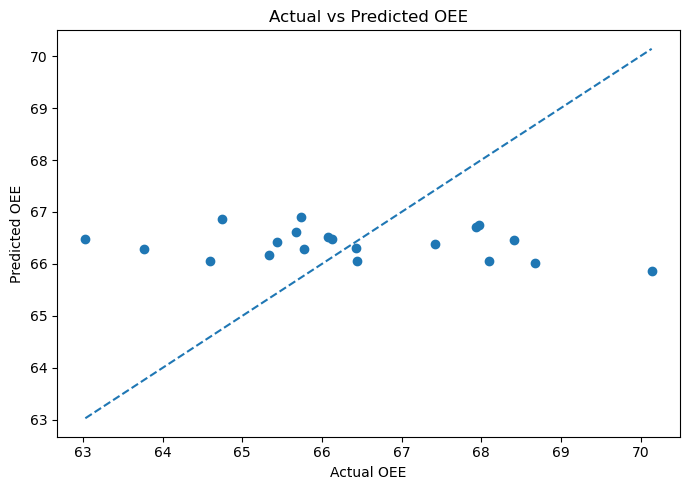

In [73]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test,y_test_pred)

min_value = min(y_test.min(),y_test_pred.min())

max_value = max(y_test.max(),y_test_pred.max())

plt.plot([min_value, max_value],[min_value, max_value],linestyle="--")

plt.xlabel("Actual OEE")
plt.ylabel("Predicted OEE")
plt.title("Actual vs Predicted OEE")
plt.tight_layout()
plt.show()

### Feature Interpretation 

In [74]:
if best_model_name == "Linear Regression":
    coef_df = pd.DataFrame({"Feature": features,"Coefficient": best_model.named_steps["model"].coef_})
    print("Linear Regression Coefficients")
    display(coef_df.sort_values("Coefficient", ascending=False))

else:
    importance_df = pd.DataFrame({"Feature": features,"Importance": best_model.feature_importances_})
    print("Feature Importance")
    display(importance_df.sort_values("Importance", ascending=False))

Linear Regression Coefficients


,Feature,Coefficient
7,Maintenance_Flag_Lag_1,0.229120
1,OEE_Lag_1,0.120010
6,Rej_Qty_Lag_1,0.064988
5,Prod_Qty_Lag_1,0.031767
2,Avail_Hrs_Lag_1,0.027706
3,MC_Running_Hrs_Lag_1,0.026569
4,Total_DT_Lag_1,0.000721
0,Machine_Age,-0.083454


### Save the complete model object 

In [75]:
# We save the fitted model pipeline itself.
# For Linear Regression this includes the StandardScaler + model.
# Therefore prediction uses exactly the same preprocessing as training.

model_data = {"model": best_model,"features": features,"model_name": best_model_name,"target": target}

with open("OEE_Tomorrow_Model.pkl", "wb") as file:
    pickle.dump(model_data, file)

print("MODEL SAVED")
print("File: OEE_Tomorrow_Model.pkl")

MODEL SAVED
File: OEE_Tomorrow_Model.pkl


### Project Summary 

In [76]:
#Key correction:
#Lag features were created only after sorting by Machine_No and Date.
#Scaling is handled inside the model pipeline and is fitted only on training data.

print("PROJECT COMPLETED")
print("Project       : Next-Day OEE Prediction")
print("Best Model    :", best_model_name)
print("MAE           :", round(final_mae, 2))
print("RMSE          :", round(final_rmse, 2))
print("MAPE          :", round(final_mape, 2), "%")
print("R2            :", round(final_r2, 2))
print("Saved Model   :", "OEE_Tomorrow_Model.pkl")

PROJECT COMPLETED
Project       : Next-Day OEE Prediction
Best Model    : Linear Regression
MAE           : 1.48
RMSE          : 1.83
MAPE          : 2.23 %
R2            : -0.12
Saved Model   : OEE_Tomorrow_Model.pkl
